# Watch First-Order Optimizers Move

This notebook follows the visual idea of the SDS431 first-order demo:
draw contours, overlay optimizer trajectories, and compare objective values.
We put gradient descent, heavy-ball momentum, Nesterov-style momentum,
AdaGrad, RMSProp, and Adam on the Beale and Rosenbrock functions.

Run the cells in order. There is no dataset to download. Learning rates are
chosen separately for clear, stable paths. An equal numerical rate would not
mean an equal effective step across these algorithms.

## Heavy-ball and Nesterov are different

With \(g_t=\nabla f(\theta_t)\), heavy-ball uses the buffer

$$b_t=\mu b_{t-1}+g_t,\qquad
  \theta_{t+1}=\theta_t-\eta b_t.$$

For a fixed learning rate, this is equivalently

$$\theta_{t+1}
  =\theta_t-\eta g_t+\mu(\theta_t-\theta_{t-1}).$$

The last term carries forward the previous displacement, giving the
heavy-ball method its name. Nesterov's idea is to anticipate that motion
before committing to the next step. In PyTorch, the Nesterov option uses
the same buffer but takes direction

$$d_t=g_t+\mu b_t=(1+\mu)g_t+\mu^2b_{t-1}.$$

The extra current-gradient term helps the direction turn when new gradients
disagree with old momentum. This is the lookahead-inspired form used by
PyTorch; it does not request a second gradient evaluation at a lookahead
point. Muon makes the same choice before orthogonalizing a matrix update.
See the [PyTorch SGD update](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html)
and [Muon update](https://docs.pytorch.org/docs/stable/generated/torch.optim.Muon.html).

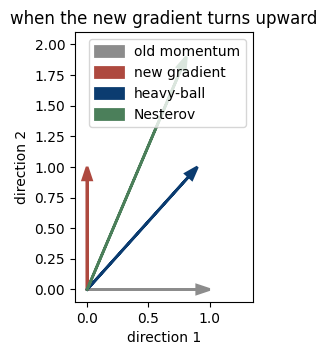

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mu = .9
old = np.array([1., 0.])
new = np.array([0., 1.])
heavy = mu * old + new
nesterov = new + mu * heavy
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for label, vector, color in [
    ('old momentum', old, '0.55'), ('new gradient', new, '#ae493f'),
    ('heavy-ball', heavy, '#0b3c70'), ('Nesterov', nesterov, '#4b7f5a')
]:
    ax.arrow(0, 0, *vector, color=color, head_width=.07,
             length_includes_head=True, linewidth=2, label=label)
ax.set(xlim=(-.1, 1.35), ylim=(-.1, 2.1), xlabel='direction 1',
       ylabel='direction 2', title='when the new gradient turns upward')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='upper right')
plt.show()

## Read the update rules in one place

The state arrays \(m\) and \(v\) persist across steps. Heavy-ball uses
accumulated gradients; Nesterov adds the current-gradient correction.
AdaGrad sums squared gradients, RMSProp discounts them, and Adam combines
discounted first and second moments with startup bias correction. The
function records the initial point and every finite subsequent iterate.

In [2]:
METHODS = ['GD', 'Heavy-ball', 'Nesterov',
           'AdaGrad', 'RMSProp', 'Adam']

def optimize(value, gradient, start, method, lr, steps,
             mu=.9, beta2=.99, eps=1e-8):
    theta = np.asarray(start, float).copy()
    m = np.zeros_like(theta)
    v = np.zeros_like(theta)
    path, values = [theta.copy()], [float(value(theta))]
    for t in range(1, steps + 1):
        g = np.asarray(gradient(theta), float)
        if method == 'GD':
            direction = g
        elif method in ('Heavy-ball', 'Nesterov'):
            m = mu * m + g
            direction = m if method == 'Heavy-ball' else g + mu * m
        elif method == 'AdaGrad':
            v += g * g
            direction = g / (np.sqrt(v) + eps)
        elif method == 'RMSProp':
            v = beta2 * v + (1-beta2) * g * g
            direction = g / (np.sqrt(v) + eps)
        elif method == 'Adam':
            m = mu * m + (1-mu) * g
            v = beta2 * v + (1-beta2) * g * g
            direction = (m/(1-mu**t)) / (np.sqrt(v/(1-beta2**t)) + eps)
        else:
            raise ValueError(method)
        theta = theta - lr * direction
        current = float(value(theta))
        if not np.all(np.isfinite(theta)) or not np.isfinite(current):
            break
        path.append(theta.copy())
        values.append(current)
    return np.array(path), np.array(values)

def compare(value, gradient, start, rates, steps):
    return {method: optimize(value, gradient, start, method,
                             rates[method], steps) for method in METHODS}

def show_results(value, results, bounds, optimum, title):
    a = np.linspace(*bounds[0], 240)
    b = np.linspace(*bounds[1], 240)
    A, B = np.meshgrid(a, b)
    Z = np.log10(value(np.stack([A, B], axis=-1)) + 1e-5)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    axes[0].contour(A, B, Z, levels=np.linspace(-3, 3.5, 18),
                    colors='0.78', linewidths=.7)
    for method, (path, values) in results.items():
        axes[0].plot(path[:,0], path[:,1], lw=1.5, label=method)
        axes[1].semilogy(np.maximum(values, 1e-12), lw=1.5, label=method)
    axes[0].scatter([optimum[0]], [optimum[1]], marker='*',
                    color='black', s=120, zorder=5)
    axes[0].set(xlabel='$\\theta_1$', ylabel='$\\theta_2$',
                xlim=bounds[0], ylim=bounds[1], title=title+' paths')
    axes[1].set(xlabel='optimizer step', ylabel='$f(\\theta_t)$',
                title=title+' objective')
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

def final_table(results, rates):
    return pd.DataFrame([
        {'method': name, 'learning rate': rates[name],
         'recorded steps': len(path)-1, 'final objective': values[-1],
         'final point': np.round(path[-1], 3)}
        for name, (path, values) in results.items()
    ])

## Beale's curved valley

$$f(x,y)=(1.5-x+xy)^2+(2.25-x+xy^2)^2+(2.625-x+xy^3)^2.$$

Its minimum is \(f(3,0.5)=0\). Each run begins at \((1,1)\). The
contours show where a method travels; the right panel shows when it makes
progress. The star marks the minimum. This is a visual comparison, not a
ranking of tuned optimizers.

,method,learning rate,recorded steps,final objective,final point
0,GD,0.010,500,0.00142,"[2.91, 0.477]"
1,Heavy-ball,0.006,500,0.00000,"[3.0, 0.5]"
2,Nesterov,0.004,500,0.00000,"[3.0, 0.5]"
3,AdaGrad,0.150,500,0.00335,"[2.866, 0.464]"
4,RMSProp,0.012,500,0.00003,"[2.987, 0.497]"
5,Adam,0.040,500,0.00000,"[3.0, 0.5]"


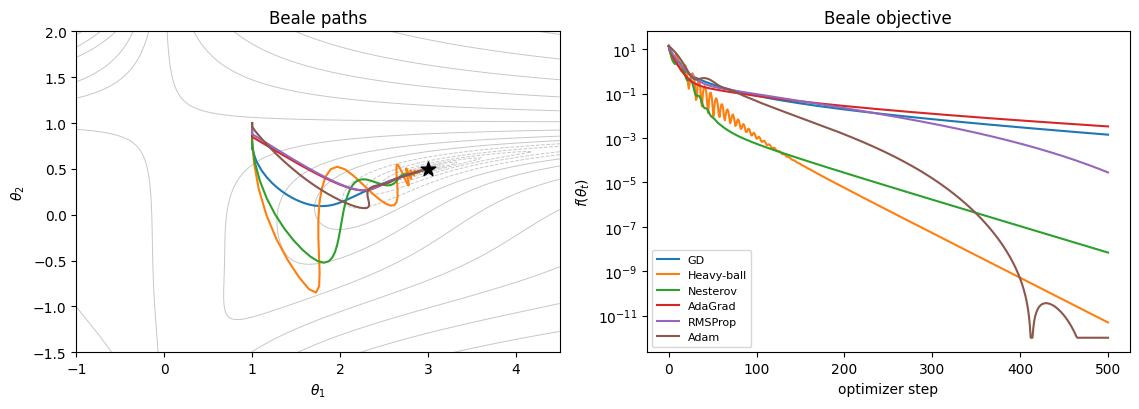

In [3]:
def beale(theta):
    x, y = theta[...,0], theta[...,1]
    return ((1.5-x+x*y)**2 + (2.25-x+x*y*y)**2
            + (2.625-x+x*y**3)**2)

def beale_grad(theta):
    x, y = theta
    r = np.array([1.5-x+x*y, 2.25-x+x*y*y, 2.625-x+x*y**3])
    return np.array([
        2*np.dot(r, [-1+y, -1+y*y, -1+y**3]),
        2*x*np.dot(r, [1, 2*y, 3*y*y])
    ])

BEALE_RATES = {'GD': .01, 'Heavy-ball': .006, 'Nesterov': .004,
               'AdaGrad': .15, 'RMSProp': .012, 'Adam': .04}
beale_results = compare(beale, beale_grad, [1.,1.], BEALE_RATES, 500)
display(final_table(beale_results, BEALE_RATES).round(5))
show_results(beale, beale_results, ((-1,4.5),(-1.5,2)),
             (3,.5), 'Beale')

## Rosenbrock's narrow, bent valley

$$f(x,y)=(1-x)^2+100(y-x^2)^2.$$

Its minimum is \(f(1,1)=0\). Each run begins at \((-1.5,1.5)\).
Momentum may overshoot across the narrow valley, and adaptive methods
rescale coordinates. Early progress need not predict the final result.

,method,learning rate,recorded steps,final objective,final point
0,GD,0.0010,1500,0.28536,"[0.466, 0.215]"
1,Heavy-ball,0.0005,1500,0.00032,"[0.982, 0.964]"
2,Nesterov,0.0004,1500,0.00177,"[0.958, 0.918]"
3,AdaGrad,0.0800,1500,3.91989,"[-0.979, 0.964]"
4,RMSProp,0.0040,1500,0.04019,"[0.806, 0.655]"
5,Adam,0.0250,1500,0.00087,"[0.999, 1.0]"


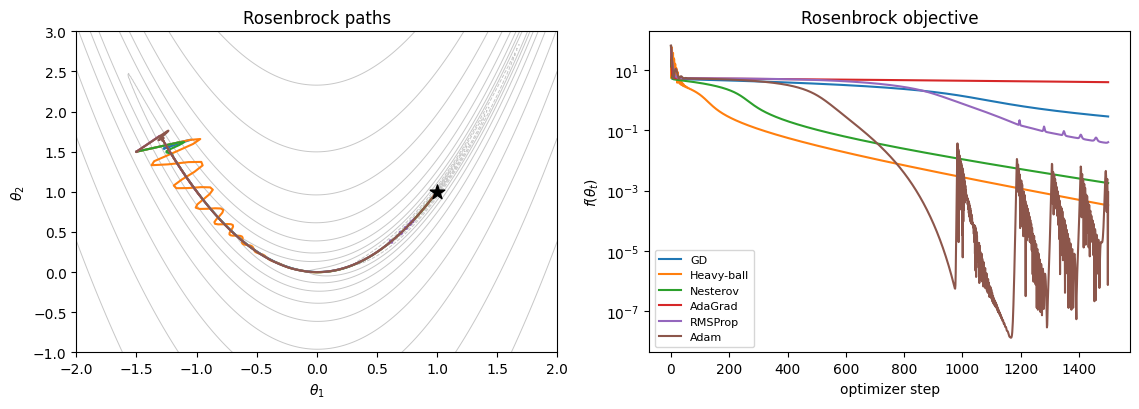

In [4]:
def rosenbrock(theta):
    x, y = theta[...,0], theta[...,1]
    return (1-x)**2 + 100*(y-x*x)**2

def rosenbrock_grad(theta):
    x, y = theta
    return np.array([-2*(1-x)-400*x*(y-x*x), 200*(y-x*x)])

ROSEN_RATES = {'GD': .001, 'Heavy-ball': .0005, 'Nesterov': .0004,
               'AdaGrad': .08, 'RMSProp': .004, 'Adam': .025}
rosen_results = compare(rosenbrock, rosenbrock_grad, [-1.5,1.5],
                        ROSEN_RATES, 1500)
display(final_table(rosen_results, ROSEN_RATES).round(5))
show_results(rosenbrock, rosen_results, ((-2,2),(-1,3)),
             (1,1), 'Rosenbrock')

## Learning-rate sensitivity

Keep the Rosenbrock objective and starting point fixed. Vary only the
learning rate for heavy-ball and Nesterov. A large rate can overshoot or
diverge; a small one can spend the whole budget in the valley. A short
recorded path means divergence, not successful early stopping. The plot
clips objective values above \(10^3\) so that one diverging run does not
hide the other curves; the table retains its actual final value.

/var/folders/dw/twkl7xz54f59zmk2mt5tr7t40000gn/T/ipykernel_40369/745626355.py:3: RuntimeWarning: overflow encountered in scalar power
  return (1-x)**2 + 100*(y-x*x)**2


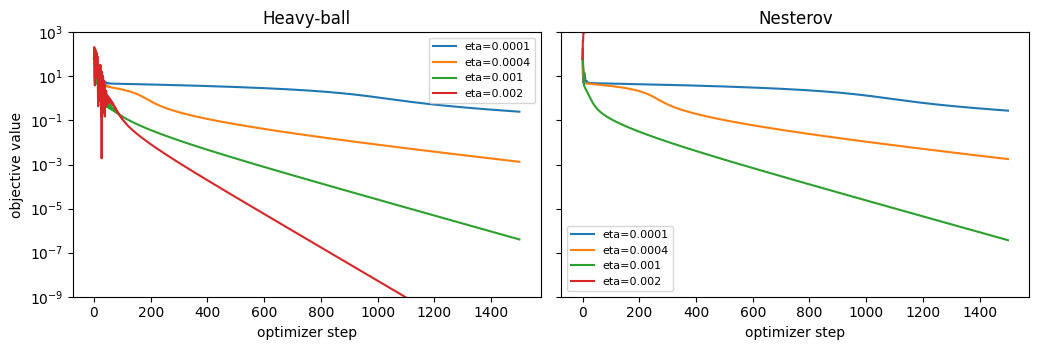

,method,learning rate,recorded steps,final objective
0,Heavy-ball,0.0001,1500,2.502700e-01
1,Heavy-ball,0.0004,1500,1.330000e-03
2,Heavy-ball,0.0010,1500,0.000000e+00
3,Heavy-ball,0.0020,1500,0.000000e+00
4,Nesterov,0.0001,1500,2.792100e-01
5,Nesterov,0.0004,1500,1.770000e-03
6,Nesterov,0.0010,1500,0.000000e+00
7,Nesterov,0.0020,7,5.599431e+131


In [5]:
rates_to_try = [.0001, .0004, .001, .002]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
rows = []
for ax, method in zip(axes, ['Heavy-ball', 'Nesterov']):
    for lr in rates_to_try:
        path, values = optimize(rosenbrock, rosenbrock_grad,
                                [-1.5,1.5], method, lr, 1500)
        rows.append({'method': method, 'learning rate': lr,
                     'recorded steps': len(values)-1,
                     'final objective': values[-1]})
        ax.semilogy(np.clip(values, 1e-12, 1e3), label=f'eta={lr:g}')
    ax.set(xlabel='optimizer step', title=method)
    ax.legend(fontsize=8)
axes[0].set_ylabel('objective value')
axes[0].set_ylim(1e-9, 1e3)
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(5))

## Carry the picture to neural networks

Heavy-ball follows a gradient buffer; Nesterov-style momentum adds a
current-gradient correction. AdaGrad retains every squared gradient,
RMSProp discounts old squares, and Adam combines both moment types.
These two-dimensional pictures reveal mechanisms. The separate MLP
notebook compares the methods on thousands of parameters and includes
Muon, which orthogonalizes updates of hidden weight matrices.